In [1]:
# Import packages and the current project library.
from pathlib import Path
import sys
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import CoolProp.CoolProp as CP

PROJECT_ROOT = Path(r'D:/eBATS')
sys.path.insert(0, str(PROJECT_ROOT))
import lib.BTMS_model as BTMS_model
BTMS_model = importlib.reload(BTMS_model)
print(f'Model library: {BTMS_model.__file__}')

Model library: D:\eBATS\lib\BTMS_model.py


In [2]:
# Configure the case, input data and output files.
CASE_ID = 'C0019'
REVISION = 'R00'
RESULT_BASENAME = f'{CASE_ID}{REVISION}_PARK_APCM_1D_EVAL'
RESULT_DATA_DIR = PROJECT_ROOT / 'data' / CASE_ID
RESULT_EXCEL_PATH = RESULT_DATA_DIR / f'{RESULT_BASENAME}.xlsx'
FIGURE_DIR = PROJECT_ROOT / 'out' / CASE_ID
SOURCE_NOTEBOOK = 'C0019_PARK_APCM_1D_EVAL.ipynb'

MISSION_KEY = 'short'
MISSION_DISTANCE_KM = 50.0
SIM_DURATION_S = 1293.0
DT = 1.0
BATTERY_PROPS = dict(
    m_bat=48e-3, cp_bat=830.0, D_bat=18e-3, H_bat=65e-3, k_bat_radial=1.5,
)
# CFD axial conductivity is 3.5 W/(m K); axial conduction is not resolved here.
PCM_PROPS = dict(
    material='Sun PW/EG, 10 wt% EG',
    rho_pcm=958.0,
    cp_pcm=2394.0,
    L_pcm=203000.0,
    k_pcm=2.97,
    T_melt_start=32.0,
    T_melt_end=36.0,
    thickness_m=1e-3,
)
MODULE_LAYOUT = dict(N_r=16, N_c=20, S_L_m=22e-3)
AIR_SETTINGS = dict(V_air=1.5, T_air=25.0, p_air=101325.0, fluid='Air', velocity_weight=0.5, htc_correction_factor=0.971)
SOLVER_SETTINGS = dict(tol=1e-6, maxiter=1000)

# Follow C0008: module width divided by the transverse cell count.
# Use the PCM outer diameter when calculating the module width.
CHANNEL_WIDTH_MODE = 'C0008_finite_reference'  # Or 'periodic_pitch'.

# Match the Downloads C0016 mixed characteristic velocity.
# Local air properties update HTC; inlet properties retain a fixed mass flow.
HTC_VELOCITY_BASIS = 'C0016_weighted'

print(pd.Series(PCM_PROPS, name='Sun PCM'))
print(f'Inlet velocity: {AIR_SETTINGS["V_air"]} m/s; dt: {DT} s')

material        Sun PW/EG, 10 wt% EG
rho_pcm                        958.0
cp_pcm                        2394.0
L_pcm                       203000.0
k_pcm                           2.97
T_melt_start                    32.0
T_melt_end                      36.0
thickness_m                    0.001
Name: Sun PCM, dtype: object
Inlet velocity: 1.5 m/s; dt: 1.0 s


In [3]:
def calculate_apcm_geometry(battery, pcm, layout, width_mode='C0008_finite_reference'):
    """Return geometry for one representative parallel flow strip."""
    D_bat = battery['D_bat']
    height = battery['H_bat']
    r_inner = D_bat / 2.0
    r_outer = r_inner + pcm['thickness_m']
    D_outer = 2.0 * r_outer
    S_L = layout['S_L_m']
    S_T = 2.0 * S_L / np.sqrt(3.0)
    S_D = np.hypot(S_L, S_T / 2.0)
    gap = S_T - D_outer
    if gap <= 0.0:
        raise ValueError('PCM shells touch or overlap; increase the cell pitches.')
    if width_mode == 'periodic_pitch':
        W_channel = S_T
    elif width_mode == 'C0008_finite_reference':
        W_channel = (D_outer + (layout['N_r'] - 1) * S_T) / layout['N_r']
    else:
        raise ValueError(f'Unknown channel width mode: {width_mode}')
    # Quasi-steady volume-mean-to-surface resistance for a uniformly heated cylinder.
    # This approximation includes radial conduction only.
    R_bat_internal = 1.0 / (8.0 * np.pi * battery['k_bat_radial'] * height)
    R_pcm_shell = np.log(r_outer/r_inner) / (2.0*np.pi*pcm['k_pcm']*height)
    R_bat_pcm_total = R_bat_internal + R_pcm_shell
    return dict(
        D_outer_m=D_outer, S_L_m=S_L, S_T_m=S_T, S_D_m=S_D,
        clear_gap_m=gap, W_air_channel_m=W_channel,
        W_module_inlet_m=layout['N_r'] * W_channel,
        L_array_envelope_m=D_outer + (layout['N_c'] - 1) * S_L,
        A_cool_cs_m2=W_channel * height,
        A_throat_strip_m2=(W_channel - D_outer) * height,
        A_pcm_air_per_cell_m2=np.pi * D_outer * height,
        m_pcm_per_cell_kg=pcm['rho_pcm'] * np.pi * (r_outer**2-r_inner**2) * height,
        R_bat_internal_per_cell_K_W=R_bat_internal,
        R_pcm_per_cell_K_W=R_pcm_shell,
        R_bat_pcm_per_cell_K_W=R_bat_pcm_total,
    )


geometry = calculate_apcm_geometry(
    BATTERY_PROPS, PCM_PROPS, MODULE_LAYOUT, CHANNEL_WIDTH_MODE,
)
geometry_table = pd.DataFrame([geometry])
display(geometry_table.T.rename(columns={0: 'value'}))
print(f'PCM outer diameter: {geometry["D_outer_m"]*1000:.3f} mm')
print(f'ST = SD: {geometry["S_T_m"]*1000:.3f} mm')
print(f'Clear gap: {geometry["clear_gap_m"]*1000:.3f} mm')
print(f'Inlet width per strip: {geometry["W_air_channel_m"]*1000:.3f} mm')
print(f"Battery internal resistance: {geometry['R_bat_internal_per_cell_K_W']:.6f} K/W")
print(f"PCM shell resistance: {geometry['R_pcm_per_cell_K_W']:.6f} K/W")
print(f"Total battery-to-PCM resistance: {geometry['R_bat_pcm_per_cell_K_W']:.6f} K/W")

                                value
D_outer_m                    0.020000
S_L_m                        0.022000
S_T_m                        0.025403
S_D_m                        0.025403
clear_gap_m                  0.005403
W_air_channel_m              0.025066
W_module_inlet_m             0.401051
L_array_envelope_m           0.438000
A_cool_cs_m2                 0.001629
A_throat_strip_m2            0.000329
A_pcm_air_per_cell_m2        0.004084
m_pcm_per_cell_kg            0.003717
R_bat_internal_per_cell_K_W  0.408090
R_pcm_per_cell_K_W           0.086862
R_bat_pcm_per_cell_K_W       0.494951
PCM outer diameter: 20.000 mm
ST = SD: 25.403 mm
Clear gap: 5.403 mm
Inlet width per strip: 25.066 mm
Battery internal resistance: 0.408090 K/W
PCM shell resistance: 0.086862 K/W
Total battery-to-PCM resistance: 0.494951 K/W


In [4]:
# Read the short-mission volumetric heat report used by C0010.
POWER_FILE = PROJECT_ROOT / 'data' / 'C0010' / '1293.out'
heat_report = pd.read_csv(
    POWER_FILE, sep=r'\s+', skiprows=3,
    names=['Time Step', 'report-def-0', 'flow-time'], dtype=float,
)
# Keep the last value at each time after a report restart, as in C0010.
heat_report = heat_report.sort_values('flow-time', kind='stable').drop_duplicates(
    'flow-time', keep='last',
)
CELL_VOLUME_M3 = np.pi / 4.0 * BATTERY_PROPS['D_bat']**2 * BATTERY_PROPS['H_bat']
heat_report['Q_cell_W'] = heat_report['report-def-0'] * CELL_VOLUME_M3

num_steps = int(round(SIM_DURATION_S / DT))
time_s = np.arange(num_steps + 1) * DT

# Use the sample at each interval start; the terminal 1293 s sample is excluded.
power_source_time_s = np.floor(np.round(time_s[:-1], 9))
power_generation_W = heat_report.set_index('flow-time').loc[
    power_source_time_s, 'Q_cell_W',
].to_numpy(dtype=float)
heat_input_table = pd.DataFrame({
    'interval_start_s': time_s[:-1],
    'interval_end_s': time_s[1:],
    'source_time_s': power_source_time_s,
    'Q_cell_W': power_generation_W,
})

temperature_K = AIR_SETTINGS['T_air'] + 273.15
pressure = AIR_SETTINGS['p_air']
fluid = AIR_SETTINGS['fluid']
air_props = dict(
    mu_air=CP.PropsSI('V', 'T', temperature_K, 'P', pressure, fluid),
    rho_air=CP.PropsSI('D', 'T', temperature_K, 'P', pressure, fluid),
    cp_air=CP.PropsSI('C', 'T', temperature_K, 'P', pressure, fluid),
    k_air=CP.PropsSI('L', 'T', temperature_K, 'P', pressure, fluid),
)
air_props['Pr_air'] = air_props['cp_air'] * air_props['mu_air'] / air_props['k_air']
print(f'{num_steps} steps; {SIM_DURATION_S:.1f} s; {DT:.3f} s per step')
print(f'Heat input: {power_generation_W.min():.3f} to {power_generation_W.max():.3f} W/cell')

1293 steps; 1293.0 s; 1.000 s per step
Heat input: 0.036 to 3.841 W/cell


In [5]:
def calculate_segment_htc(temperature_C, air_settings, characteristic_velocity, diameter):
    """Calculate HTC with local air properties and a fixed correction factor."""
    temperature_K = np.asarray(temperature_C, dtype=float) + 273.15
    pressure = air_settings['p_air']
    fluid = air_settings['fluid']
    mu = CP.PropsSI('V', 'T', temperature_K, 'P', pressure, fluid)
    rho = CP.PropsSI('D', 'T', temperature_K, 'P', pressure, fluid)
    cp = CP.PropsSI('C', 'T', temperature_K, 'P', pressure, fluid)
    conductivity = CP.PropsSI('L', 'T', temperature_K, 'P', pressure, fluid)
    prandtl = cp * mu / conductivity
    reynolds = rho * characteristic_velocity * diameter / mu
    correction = np.full_like(reynolds, air_settings['htc_correction_factor'], dtype=float)
    nusselt = np.array([
        BTMS_model.zukauskas_nusellet(re, pr, eps, pr)
        for re, pr, eps in zip(reynolds, prandtl, correction)
    ])
    return nusselt * conductivity / diameter, reynolds, nusselt


def run_evaluation_case(
    time_s, power_generation_W, battery, pcm, layout, air_settings,
    air_props, geometry, solver_settings, htc_velocity_basis='C0016_weighted',
):
    """Advance the coupled battery/PCM/air model over one mission."""
    dt = float(time_s[1] - time_s[0])
    n_steps = len(time_s) - 1
    n_segments = layout['N_c']
    inlet_temperature = air_settings['T_air']
    inlet_velocity = air_settings['V_air']
    D_outer = geometry['D_outer_m']
    gap_velocity = inlet_velocity * geometry['S_T_m'] / geometry['clear_gap_m']
    if htc_velocity_basis == 'C0016_weighted':
        weight = air_settings['velocity_weight']
        correlation_velocity = weight * gap_velocity + (1.0-weight) * inlet_velocity
    elif htc_velocity_basis == 'C0008_inlet':
        correlation_velocity = inlet_velocity
    elif htc_velocity_basis == 'ideal_bank_gap':
        if not np.isclose(geometry['W_air_channel_m'], geometry['S_T_m']):
            raise ValueError('ideal_bank_gap requires periodic-pitch flow strips.')
        correlation_velocity = gap_velocity
    else:
        raise ValueError(f'Unknown HTC velocity basis: {htc_velocity_basis}')

    # Report inlet-condition references; the time loop updates each segment HTC.
    initial_htc, initial_re, initial_nu = calculate_segment_htc(
        np.full(n_segments, inlet_temperature), air_settings,
        correlation_velocity, D_outer,
    )
    Re_air = float(initial_re[0])
    Nu_air = float(initial_nu[0])
    h_air = float(initial_htc[0])

    T_bat = np.full(n_segments, inlet_temperature, dtype=float)
    T_pcm = T_bat.copy()
    T_air = T_bat.copy()
    T_bat_history = np.empty((n_steps + 1, n_segments))
    T_pcm_history = np.empty_like(T_bat_history)
    T_air_history = np.empty_like(T_bat_history)
    T_bat_history[0] = T_bat
    T_pcm_history[0] = T_pcm
    T_air_history[0] = T_air
    maximum_residual_W = 0.0
    htc_history = np.empty((n_steps, n_segments))

    args = dict(
        dt=dt, num_cell_seg=1.0, is_cool=True, upwind_scheme=False,
        m_bat=battery['m_bat'], cp_bat=battery['cp_bat'],
        m_pcm=geometry['m_pcm_per_cell_kg'], cp_pcm=pcm['cp_pcm'],
        L_pcm=pcm['L_pcm'], T_melt_start=pcm['T_melt_start'],
        T_melt_end=pcm['T_melt_end'],
        R_bat_pcm=geometry['R_bat_pcm_per_cell_K_W'],
        T_cool_in=inlet_temperature, u_cool_in=inlet_velocity,
        A_cool_cs=geometry['A_cool_cs_m2'],
        A_HT_seg=geometry['A_pcm_air_per_cell_m2'], htc_cool=h_air,
        cp_cool=air_props['cp_air'], rho_cool=air_props['rho_air'],
    )
    for step in range(n_steps):
        # Estimate segment mean air temperatures from the previous solved state.
        upstream_air = np.concatenate(([inlet_temperature], T_air[:-1]))
        segment_mean_air = 0.5 * (upstream_air + T_air)
        htc_seg, _, _ = calculate_segment_htc(
            segment_mean_air, air_settings, correlation_velocity, D_outer,
        )
        htc_history[step] = htc_seg
        args.update(
            htc_cool=htc_seg,
            T_bat_pre=T_bat, T_pcm_pre=T_pcm, T_cool_pre=T_air,
            Q_gen=power_generation_W[step],
            T_cool_out=max(float(T_air[-1]), inlet_temperature),
        )
        try:
            state = BTMS_model.solve_coolant_pcm_temperature_distribution(
                args, tol=solver_settings['tol'],
                maxiter=solver_settings['maxiter'], debug=False,
            )
        except RuntimeError as error:
            raise RuntimeError(
                f'APCM solve failed at step {step}, t={time_s[step]:.3f} s; '
                f'Q_gen={power_generation_W[step]:.6g} W/cell; '
                f'previous PCM range={T_pcm.min():.6g} to {T_pcm.max():.6g} degC. '
                f'{error}'
            ) from error
        maximum_residual_W = max(
            maximum_residual_W,
            float(np.max(np.abs(BTMS_model.cal_pcm_power_residual(state, args)))),
        )
        T_air, T_pcm, T_bat = np.split(state, 3)
        T_bat_history[step + 1] = T_bat
        T_pcm_history[step + 1] = T_pcm
        T_air_history[step + 1] = T_air
        if (step + 1) % max(1, n_steps // 10) == 0:
            print(f'{step+1}/{n_steps}: t={time_s[step+1]:.1f} s; '
                  f'Tbat,max={T_bat.max():.3f} degC', flush=True)

    return dict(
        time_s=time_s.copy(), T_bat_history_C=T_bat_history,
        T_pcm_history_C=T_pcm_history, T_air_history_C=T_air_history,
        Tmax_C=T_bat_history.max(axis=1), Tmin_C=T_bat_history.min(axis=1),
        DeltaT_C=np.ptp(T_bat_history, axis=1),
        Tpcm_max_C=T_pcm_history.max(axis=1), Tpcm_min_C=T_pcm_history.min(axis=1),
        Tair_out_C=T_air_history[:, -1],
        Re_air=float(Re_air), Nu_air=float(Nu_air), h_air_W_m2K=float(h_air),
        inlet_velocity_m_s=inlet_velocity, ideal_gap_velocity_m_s=gap_velocity,
        htc_velocity_basis=htc_velocity_basis,
        characteristic_velocity_m_s=float(correlation_velocity),
        velocity_weight=float(air_settings['velocity_weight']),
        htc_correction_factor=float(air_settings['htc_correction_factor']),
        htc_temperature_basis='previous_step_segment_mean_air',
        htc_history_W_m2K=htc_history,
        htc_min_W_m2K=float(htc_history.min()),
        htc_max_W_m2K=float(htc_history.max()),
        m_dot_air_per_strip_kg_s=air_props['rho_air'] * inlet_velocity * geometry['A_cool_cs_m2'],
        m_pcm_module_kg=geometry['m_pcm_per_cell_kg'] * layout['N_r'] * layout['N_c'],
        maximum_balance_residual_W=maximum_residual_W,
    )

In [6]:
# Run the selected Sun-PCM evaluation case.
results = run_evaluation_case(
    time_s, power_generation_W, BATTERY_PROPS, PCM_PROPS, MODULE_LAYOUT,
    AIR_SETTINGS, air_props, geometry, SOLVER_SETTINGS, HTC_VELOCITY_BASIS,
)
peak = int(np.argmax(results['Tmax_C']))
print(f'Mission maximum battery temperature: {results["Tmax_C"][peak]:.3f} degC')
print(f'Time of maximum temperature: {results["time_s"][peak]:.1f} s')
print(f'Mission maximum battery temperature spread: {results["DeltaT_C"].max():.3f} K')
print(f'Maximum balance residual: {results["maximum_balance_residual_W"]:.3g} W')

129/1293: t=129.0 s; Tbat,max=27.487 degC
258/1293: t=258.0 s; Tbat,max=28.071 degC
387/1293: t=387.0 s; Tbat,max=28.258 degC
516/1293: t=516.0 s; Tbat,max=28.420 degC
645/1293: t=645.0 s; Tbat,max=28.556 degC
774/1293: t=774.0 s; Tbat,max=28.659 degC
903/1293: t=903.0 s; Tbat,max=28.260 degC
1032/1293: t=1032.0 s; Tbat,max=31.611 degC
1161/1293: t=1161.0 s; Tbat,max=34.773 degC
1290/1293: t=1290.0 s; Tbat,max=36.560 degC
Mission maximum battery temperature: 36.605 degC
Time of maximum temperature: 1293.0 s
Mission maximum battery temperature spread: 1.977 K
Maximum balance residual: 1e-10 W


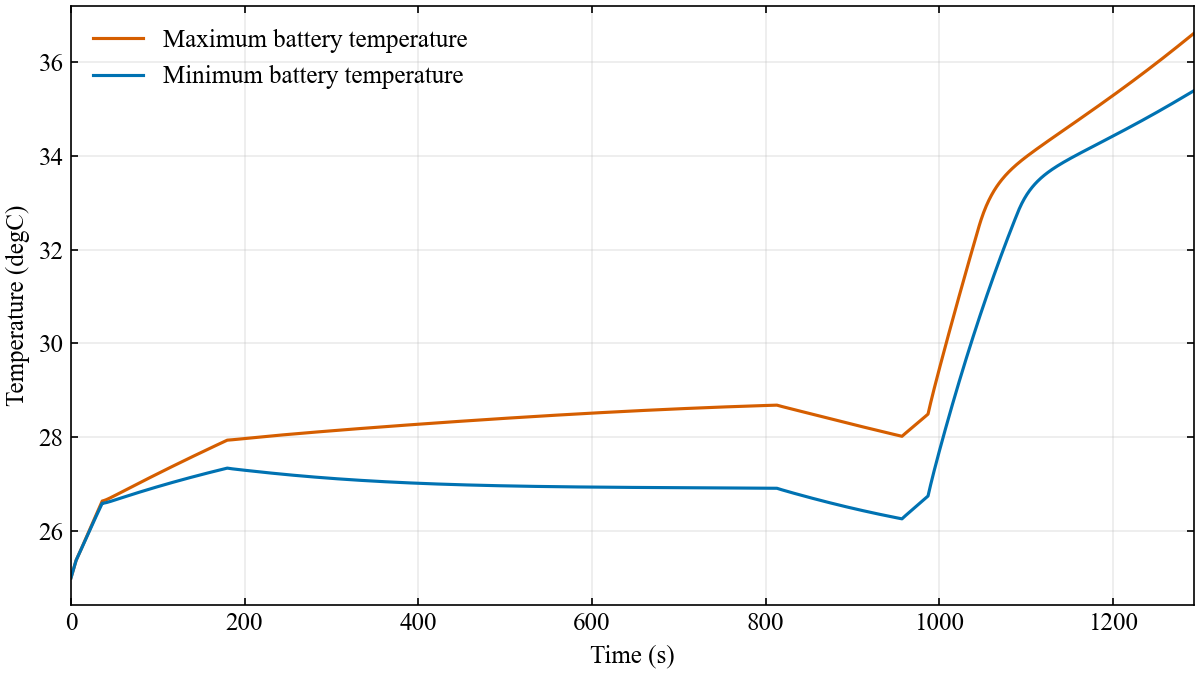

In [7]:
# Plot only the maximum and minimum battery temperatures.
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 12})
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.plot(results['time_s'], results['Tmax_C'],
        label='Maximum battery temperature', color='#D55E00')
ax.plot(results['time_s'], results['Tmin_C'],
        label='Minimum battery temperature', color='#0072B2')
ax.set(xlabel='Time (s)', ylabel='Temperature (degC)', xlim=(0, SIM_DURATION_S))
ax.grid(alpha=0.25)
ax.tick_params(direction='in', top=True, right=True)
ax.legend(frameon=False)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURE_DIR / f'{RESULT_BASENAME}.png', dpi=300)
plt.show()

In [8]:
# Export curves, node temperatures and explicit modelling assumptions.
curve_names = ['time_s', 'Tmax_C', 'Tmin_C', 'DeltaT_C',
               'Tpcm_max_C', 'Tpcm_min_C', 'Tair_out_C']
selected_table = pd.DataFrame({name: results[name] for name in curve_names})
temperature_table = pd.DataFrame({'Time Step': np.arange(len(time_s)), 'time_s': time_s})
for prefix, key in [('T_bat', 'T_bat_history_C'), ('T_pcm', 'T_pcm_history_C'),
                    ('T_air', 'T_air_history_C')]:
    for position in range(MODULE_LAYOUT['N_c']):
        temperature_table[f'{prefix} {position+1}'] = results[key][:, position]
summary = dict(
    case_id=CASE_ID, revision=REVISION, source_notebook=SOURCE_NOTEBOOK,
    simulation_duration_s=SIM_DURATION_S, dt_s=DT,
    mission_key=MISSION_KEY, mission_distance_km=MISSION_DISTANCE_KM,
    heat_source=str(POWER_FILE), raw_heat_unit='W/m3',
    cell_volume_m3=CELL_VOLUME_M3,
    channel_width_mode=CHANNEL_WIDTH_MODE,
    mission_Tmax_C=float(results['Tmax_C'].max()),
    mission_DeltaT_max_C=float(results['DeltaT_C'].max()),
    **BATTERY_PROPS, **PCM_PROPS, **MODULE_LAYOUT, **AIR_SETTINGS,
)
summary.update({key: value for key, value in results.items() if np.isscalar(value)})
summary.update(geometry)
summary_table = pd.DataFrame([summary])
RESULT_DATA_DIR.mkdir(parents=True, exist_ok=True)
with pd.ExcelWriter(RESULT_EXCEL_PATH, engine='openpyxl') as writer:
    summary_table.to_excel(writer, sheet_name='Summary', index=False)
    selected_table.to_excel(writer, sheet_name='Selected', index=False)
    temperature_table.to_excel(writer, sheet_name='Sheet1', index=False)
    geometry_table.to_excel(writer, sheet_name='Geometry', index=False)
    heat_input_table.to_excel(writer, sheet_name='Heat_input', index=False)
    htc_table = pd.DataFrame(results['htc_history_W_m2K'],
                             columns=[f'h_seg_{i+1}' for i in range(MODULE_LAYOUT['N_c'])])
    htc_table.insert(0, 'interval_start_s', time_s[:-1])
    htc_table.to_excel(writer, sheet_name='HTC', index=False)
    for sheet in writer.sheets.values():
        sheet.freeze_panes = 'A2'
        sheet.auto_filter.ref = sheet.dimensions
print(f'Saved: {RESULT_EXCEL_PATH}')

Saved: D:\eBATS\data\C0019\C0019R00_PARK_APCM_1D_EVAL.xlsx
